# Dataset de modelado y separación train/test

Arma el dataset único para la Etapa A de la consigna (`consigna/Consigna TP3.pdf`): une las features de
`3_analisis_temporal.ipynb` (lags, rolling, encoding cíclico), los pronósticos y errores de
`2_relaciones-bivariadas.ipynb` y los atributos geográficos de `4_atributos_geograficos.ipynb` en una sola tabla, define
qué filas tienen un target válido para cada variable y separa train/test por fecha.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils import AZUL, NARANJA, GRIS_TEXTO, aplicar_estilo

In [2]:
PROCESSED = '../data/processed/'
OUT = '../data/out/modelado/'

# Paleta, colormaps y funciones de gráficos: notebooks/utils.py
aplicar_estilo()

figuras = {}  # se exportan todas al final

## 1. Carga de los tres archivos a unir

In [3]:
panel = pd.read_csv(PROCESSED + 'panel_features.csv')
panel['target_hour_utc'] = pd.to_datetime(panel['target_hour_utc'], utc=True)

mediciones = pd.read_csv(PROCESSED + 'mediciones_limpias.csv')
mediciones['target_hour_utc'] = pd.to_datetime(mediciones['target_hour_utc'], utc=True)

atributos = pd.read_csv(PROCESSED + 'estaciones_atributos.csv')

print(f'panel_features:        {panel.shape[0]:>7,} filas, {panel.shape[1]:>2} columnas, {panel.station_id.nunique()} estaciones')
print(f'mediciones_limpias:    {mediciones.shape[0]:>7,} filas, {mediciones.shape[1]:>2} columnas, {mediciones.station_id.nunique()} estaciones')
print(f'estaciones_atributos:  {atributos.shape[0]:>7,} filas, {atributos.shape[1]:>2} columnas')

panel_features:        165,896 filas, 55 columnas, 466 estaciones
mediciones_limpias:    130,562 filas, 35 columnas, 498 estaciones
estaciones_atributos:      498 filas, 10 columnas


`panel_features.csv` trae sólo las 466 estaciones del cohorte con intermitencia manejable (sección 4 de
`3_analisis_temporal.ipynb`), así que es el ancla de la unión: `mediciones_limpias.csv` y `estaciones_atributos.csv`
tienen las 498 estaciones del proyecto completo y se agregan con `how='left'` sobre ese cohorte.

## 2. Unión en un único dataset de modelado

Clave de unión: `station_id` + `target_hour_utc`. Es una clave simple porque `horizonte_horas` es constante (6h en
todo el dataset: no hay pronósticos emitidos a distintos horizontes para la misma hora objetivo que compitan en la
unión). De `mediciones_limpias.csv` se traen sólo los pronósticos (`fcst_*`); el error **no** se trae de ahí -se
recalcula acá mismo, `fcst_<var> - obs_<var>`, usando el `obs_<var>` ya regularizado e imputado de `panel_features.csv`,
no el original de `mediciones_limpias.csv`.

La razón: `error_<var>` en `mediciones_limpias.csv` se calculó en `relaciones-bivariadas.ipynb` contra el obs crudo,
antes de que `3_analisis_temporal.ipynb` corrigiera saltos horarios imposibles e imputara huecos cortos en
`obs_<var>`. Traer ese error tal cual generaba dos problemas, detectados auditando el dataset ya armado: (1) filas
donde `panel_features.csv` ya tenía un `obs_<var>` imputado (hueco corto) pero el error seguía en `NaN` porque
`mediciones_limpias.csv` nunca tuvo esa observación -una oportunidad de target perdida, no un hueco real-; y (2) una
franja más chica de filas donde el error terminaba calculado contra un valor que `3_analisis_temporal.ipynb` había
descartado por salto horario imposible -una inconsistencia entre el `obs_<var>` final del dataset y el `error_<var>`
de esa misma fila. Recalcular acá, después de la unión, resuelve los dos a la vez.

In [4]:
VARIABLES_TARGET = ['temp_c', 'rh_pct', 'dewpoint_c', 'windspeed_kmh']
COLUMNAS_FCST = [f'fcst_{v}' for v in VARIABLES_TARGET] + ['fcst_pop_pct']

assert mediciones['horizonte_horas'].nunique() == 1, 'hay más de un horizonte de pronóstico: la unión por estación+hora sería ambigua'
assert not mediciones.duplicated(['station_id', 'target_hour_utc']).any(), 'mediciones_limpias tiene pares estación+hora repetidos'
assert not panel.duplicated(['station_id', 'target_hour_utc']).any(), 'panel_features tiene pares estación+hora repetidos'

dataset = panel.merge(
    mediciones[['station_id', 'target_hour_utc'] + COLUMNAS_FCST],
    on=['station_id', 'target_hour_utc'], how='left')

dataset = dataset.merge(atributos, on='station_id', how='left')

for v in VARIABLES_TARGET:
    dataset[f'error_{v}'] = dataset[f'fcst_{v}'] - dataset[f'obs_{v}']
    dataset[f'abs_error_{v}'] = dataset[f'error_{v}'].abs()

assert dataset['bioma'].notna().all(), 'alguna estación del cohorte quedó sin atributos geográficos'
print(f'dataset: {dataset.shape[0]:,} filas, {dataset.shape[1]} columnas, {dataset.station_id.nunique()} estaciones')

dataset: 165,896 filas, 77 columnas, 466 estaciones


## 3. Validez del target: no toda fila tiene un error observable

`panel_features.csv` reindexa cada estación del cohorte a la grilla horaria completa del proyecto e imputa huecos
cortos (sección 7 de `3_analisis_temporal.ipynb`) sobre `obs_<var>`, y `error_<var>` se recalcula acá mismo contra ese
`obs_<var>` ya regularizado (sección 2). Por eso ahora el error queda en `NaN` exactamente en dos casos: no hay
pronóstico para esa hora (`fcst_<var>` ausente -la columna se trae de `mediciones_limpias.csv` con `how='left'`), o no
hay observación utilizable (`obs_<var>` en `NaN` en el panel -un hueco demasiado largo para imputar, como el corte
compartido del 22/10-27/10, o la fila nunca tuvo una medición real para empezar, incluyendo las que
`relaciones-bivariadas.ipynb` descartó por diferencia imposible contra el pronóstico: más de 15°C o 120km/h). Ya no
queda un tercer caso de "la observación existía (imputada) pero nunca se calculó el error" -ese era justamente el
problema del merge anterior.

Se marca la validez por variable (cada una tiene su propia tasa de imputación) en vez de exigir las 4 a la vez, para no
descartar filas de más: una fila puede tener temperatura válida y viento imputado.

In [5]:
for v in VARIABLES_TARGET:
    dataset[f'target_valido_{v}'] = dataset[f'error_{v}'].notna()

filas = []
for v in VARIABLES_TARGET:
    valido = dataset[f'target_valido_{v}']
    imputado = dataset[f'obs_{v}_imputado']
    filas.append({
        'variable': v,
        'target_valido': int(valido.sum()),
        'target_valido_pct': round(100 * valido.mean(), 1),
        'invalido_hora_imputada': int((~valido & imputado).sum()),
        'invalido_otro_motivo': int((~valido & ~imputado).sum()),
    })

resumen_validez = pd.DataFrame(filas).set_index('variable')
resumen_validez

,target_valido,target_valido_pct,invalido_hora_imputada,invalido_otro_motivo
variable,,,,
temp_c,122547,73.9,25694,17655
rh_pct,122487,73.8,25662,17747
dewpoint_c,122616,73.9,25805,17475
windspeed_kmh,122857,74.1,25899,17140


Las 4 variables rondan el 74% de filas con target válido -mejoró varios puntos respecto de antes de este fix (ronda-
ba el 69-70%), porque ahora `error_<var>` se calcula contra el `obs_<var>` ya imputado de `panel_features.csv` en vez
de depender de que `mediciones_limpias.csv` tuviera la observación original: las ~33.000 filas por variable donde
`3_analisis_temporal.ipynb` había imputado un hueco corto dejaron de perder el target automáticamente.

De las filas inválidas que quedan, ahora `invalido_hora_imputada` significa algo más preciso que antes del fix: ya no
es "la observación estaba imputada y el error nunca se calculó" (eso ya no pasa), sino "la observación está imputada
*pero además* falta el pronóstico para esa hora" -~59% de las inválidas. El otro ~41% (`invalido_otro_motivo`) es
mayormente el propio corte compartido del 22/10-27/10 sin imputar (142 estaciones × ~120h ≈ 17.000 filas, el orden de
magnitud correcto) más el ~1,4-1,7% que `relaciones-bivariadas.ipynb` descartó por diferencia imposible contra el
pronóstico. Ninguna fila se elimina acá: cada notebook de modelado filtra por `target_valido_<variable>` según la
variable que esté entrenando, así que estos casos simplemente no entran como target, en vez de ensuciar el dataset
con un valor inventado.

## 4. Separación train/test

No corresponde un split aleatorio ni K-fold estándar: `3_analisis_temporal.ipynb` confirmó autocorrelación horaria
alta (lags 1-3) y un ciclo diario significativo en todo el cohorte, así que una fila de test cercana en el tiempo a una
fila de train estaría filtrada por información casi idéntica -el modelo no estaría prediciendo, estaría memorizando el
entorno inmediato. Tampoco hace falta un *gap* entre train y test: todas las features (lags, rolling, vecinas) miran
sólo hacia atrás (`shift(1)` o más, sección "Feature engineering" de `3_analisis_temporal.ipynb`), así que una fila de
test al principio del período de test sólo usa información de horas anteriores, reales o de train.

El corte es por fecha, igual para las 466 estaciones (no por estación): el dataset tiene 15 días (19/10 al 2/11), con un
volumen de filas por día constante en 11.184 (466 × 24 h, salvo los dos días parciales de los extremos) -el `reindex`
de `3_analisis_temporal.ipynb` garantiza una fila por estación y hora incluso durante el corte compartido del
22/10-27/10, así que esa ventana resta *validez* de target (sección 3) pero no resta filas. Se separa el último ~20 %
como test -el 31/10 en adelante-, dejando ~12 días para entrenar. Como el corte compartido cae entero dentro del
período de train, el split queda asimétrico en validez: ~80 % de targets válidos en test contra ~66-67 % en train
(sección siguiente) -no es una falla del split, es que train carga con la ventana del apagón y test no.

In [6]:
CORTE = pd.Timestamp('2026-10-31', tz='UTC')

dataset['split'] = np.where(dataset['target_hour_utc'] < CORTE, 'train', 'test')

resumen_split = dataset.groupby('split').agg(
    filas=('station_id', 'size'),
    estaciones=('station_id', 'nunique'),
    desde=('target_hour_utc', 'min'),
    hasta=('target_hour_utc', 'max'),
)
resumen_split['filas_pct'] = (100 * resumen_split['filas'] / len(dataset)).round(1)
resumen_split

,filas,estaciones,desde,hasta,filas_pct
split,,,,,
test,32620,466,2026-10-31 00:00:00+00:00,2026-11-02 21:00:00+00:00,19.7
train,133276,466,2026-10-19 02:00:00+00:00,2026-10-30 23:00:00+00:00,80.3


In [7]:
# Las 466 estaciones del cohorte aparecen en los dos splits. La validez de target es más baja en train que en test
# porque el corte compartido (22/10-27/10) cae dentro del período de train (ver celda anterior) -una asimetría
# esperada, no una señal de que el corte elegido esté mal.
resumen_validez_split = pd.concat({
    split: pd.DataFrame({
        v: {'filas': len(g), 'target_valido_pct': round(100 * g[f'target_valido_{v}'].mean(), 1)}
        for v in VARIABLES_TARGET
    }).T
    for split, g in dataset.groupby('split')
}, axis=1)
resumen_validez_split

test                       train                  
                 filas target_valido_pct     filas target_valido_pct
temp_c         32620.0              84.3  133276.0              71.3
rh_pct         32620.0              84.2  133276.0              71.3
dewpoint_c     32620.0              84.2  133276.0              71.4
windspeed_kmh  32620.0              84.5  133276.0              71.5

Chequeo visual: filas por día, coloreadas por split.

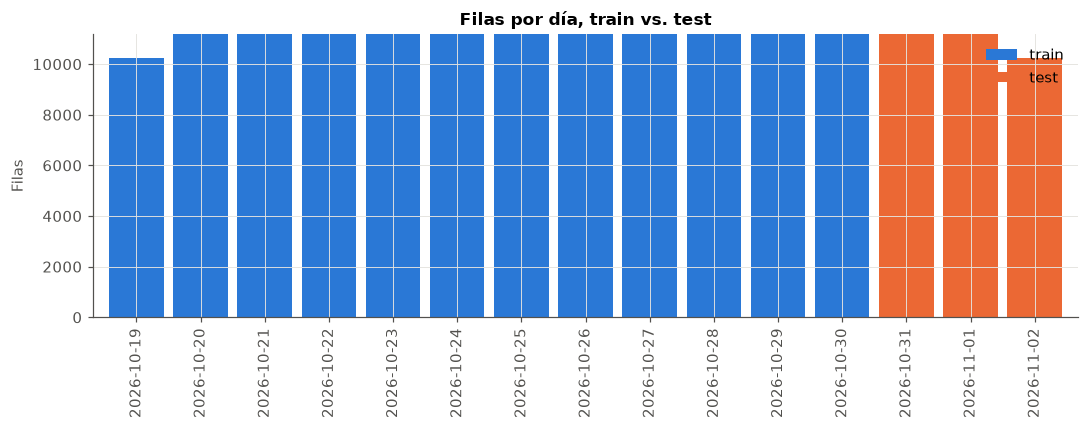

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
conteo_dia = dataset.groupby([dataset['target_hour_utc'].dt.date, 'split']).size().unstack('split').fillna(0)
conteo_dia[['train', 'test']].plot(kind='bar', stacked=True, ax=ax, color=[AZUL, NARANJA], width=0.85)
ax.set_title('Filas por día, train vs. test')
ax.set_xlabel('')
ax.set_ylabel('Filas')
ax.legend(frameon=False)
fig.tight_layout()
figuras['01_split_por_dia'] = fig

## 5. Guardado

Se guarda el dataset completo (features + pronósticos + errores + atributos geográficos + flags de validez +
columna `split`) en una sola tabla: los notebooks de modelado filtran por `split` y por `target_valido_<variable>`
según la variable que entrenen, en vez de depender de archivos train/test separados que haya que mantener
sincronizados.

In [9]:
import os

dataset.to_csv(PROCESSED + 'dataset_modelado.csv', index=False)
print(f'{PROCESSED}dataset_modelado.csv: {dataset.shape[0]:,} filas, {dataset.shape[1]} columnas')

os.makedirs(OUT, exist_ok=True)
for nombre, fig in figuras.items():
    fig.savefig(OUT + f'{nombre}.png', dpi=300, bbox_inches='tight', facecolor='white')
resumen_validez.to_csv(OUT + 'tabla_validez_target.csv')
resumen_split.to_csv(OUT + 'tabla_resumen_split.csv')
print(f'Guardados {len(figuras)} gráfico(s) y 2 tablas en {OUT}')

../data/processed/dataset_modelado.csv: 165,896 filas, 82 columnas
Guardados 1 gráfico(s) y 2 tablas en ../data/out/modelado/
